# Cross-City Transfer Learning for AQI Forecasting in Data-Scarce Indian Regions
Team Toxic (23): Arjun Srikanth, Ankit Umadi, Jayanth K.

**Research question:** With limited target fitting labels, do local models, pooled cross-city models, fine-tuning, or meta-learning yield better daily AQI forecasts? We compare each against persistence and retain negative findings.

This is a retrospective station-level study using original CPCB exports, not a city-average exposure model. The original 24–72-hour aim is implemented as nominal 1–3-day forecasts of the reported 4 PM daily AQI. Exact publication latency is unverified. Earlier seven-station pilot tests were inspected; these six target cities were chosen before this run's errors, but this is not a public preregistration.


## Data and evidence
The immutable source release has 3,820 workbooks, including empty exports. Every file is checked against its SHA256 and parsed according to its day/month layout. Summary rows are not measurements. Unmatched station IDs remain in the extraction and audit; their unresolved geography prevents their use in the city-transfer experiment. Four source values above 500 remain visible and unchanged; they are in 2017, outside this study's modeling years. No missing inputs or test truths are imputed.

The source covers a captured current roster and 2017–2025, not every historical Indian station. Calendar coverage is reporting availability, not verified monitor uptime. Original export routes and listing evidence are packaged with the dataset; this notebook consumes those files and does not claim to collect them from CPCB inside Kaggle.


In [1]:
from pathlib import Path
import os, sys, json, hashlib, time, platform
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image
roots=[p.parent for p in Path('/kaggle/input').rglob('DATASET_CARD.md') if p.parent.name=='CPCB_AQI_Source_Release_v1']
assert len(roots)==1, f'Expected one attached v1 release, found {roots}'
SOURCE=roots[0]
OUT=Path('/kaggle/working/afml_final')
OUT.mkdir(parents=True,exist_ok=True)
print('Source:',SOURCE,'Python:',platform.python_version())


Source: /kaggle/input/datasets/noqtar/cpcb-aqi-source-release-v1/CPCB_AQI_Source_Release_v1 Python: 3.13.18


## Reproducible extraction and availability checks
Functions below verify original files before building calendar-safe examples.

In [2]:
"""Immutable CPCB extraction, descriptive EDA and frozen study construction."""
from pathlib import Path
import calendar, hashlib, importlib.util, json, platform, sys, time
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

TARGETS = ['Amaravati', 'Guwahati', 'Ahmedabad', 'Pithampur', 'Ludhiana', 'Udaipur']
DEV_CITIES = ['Chandigarh', 'Dewas', 'Jalandhar', 'Ajmer']

def sha256(path):
    return hashlib.sha256(Path(path).read_bytes()).hexdigest()

def write_json(path, data):
    Path(path).write_text(json.dumps(data, indent=2, default=str))

def prepare(root, outdir):
    root, out = Path(root), Path(outdir)
    out.mkdir(parents=True, exist_ok=True)
    started = time.time()
    register = pd.read_csv(root/'file_register.csv', dtype={'station_id':str})
    meta = pd.read_csv(root/'station_metadata.csv', dtype={'site_id':str})
    assert len(register)==3820 and len(meta)==626
    assert not meta.site_id.duplicated().any()
    spec = importlib.util.spec_from_file_location('release_parser', root/'scripts/build_paper_source_coverage.py')
    parser = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(parser)
    rows, integrity = [], []
    for r in register.itertuples(index=False):
        path = root/'aqi_files'/r.filename
        assert path.stat().st_size==int(r.bytes), path
        digest = sha256(path)
        assert digest == r.sha256, path
        readings, layout, nrows, ncols = parser.parse_workbook(path, int(r.year))
        rows.extend((str(r.station_id), d, v) for d,v in readings.items())
        integrity.append({'filename':r.filename,'sha256':digest,'observations':len(readings),
                          'layout':f'{layout}_{nrows}x{ncols}',
                          'above_500':sum(v>500 for v in readings.values()),'below_zero':sum(v<0 for v in readings.values())})
    raw = pd.DataFrame(rows,columns=['station_id','date','aqi'])
    raw['date']=pd.to_datetime(raw.date)
    assert len(raw)==769129 and not raw.duplicated(['station_id','date']).any()
    assert np.isfinite(raw.aqi).all()
    raw=raw.sort_values(['station_id','date']).reset_index(drop=True)
    raw=raw.merge(meta.rename(columns={'site_id':'station_id'}),on='station_id',how='left',validate='many_to_one')
    pd.DataFrame(integrity).to_csv(out/'raw_integrity.csv',index=False)
    raw[['station_id','date','aqi','station_name','city','city_code','state']].to_csv(out/'observations.csv.gz',index=False)
    raw.loc[(raw.aqi>500)|(raw.aqi<0),['station_id','date','aqi','city']].to_csv(out/'range_flags.csv',index=False)
    raw.loc[raw.city.isna()].groupby('station_id').size().rename('observations').to_csv(out/'unmatched_ids.csv')
    matched=raw[raw.city.notna()].copy()
    matched['year']=matched.date.dt.year
    idx=pd.MultiIndex.from_product([meta.site_id.astype(str),range(2017,2026)],names=['station_id','year'])
    cov=matched.groupby(['station_id','year']).size().reindex(idx,fill_value=0).rename('observed').reset_index()
    cov['calendar_days']=cov.year.map(lambda y:366 if calendar.isleap(int(y)) else 365)
    cov['fraction']=cov.observed/cov.calendar_days
    cov=cov.merge(meta[['site_id','city','city_code','state','station_name']].rename(columns={'site_id':'station_id'}),on='station_id',validate='many_to_one')
    cov.to_csv(out/'station_year_coverage.csv',index=False)
    grid=cov.pivot(index='station_id',columns='year',values='fraction').reindex(columns=range(2020,2026))
    eligible_ids=grid.index[(grid>=.8).all(axis=1)]
    eligible=meta[meta.site_id.astype(str).isin(eligible_ids)].copy()
    rank=cov[cov.year.between(2020,2023)].groupby('station_id')['observed'].sum()
    eligible['training_observed_days']=eligible.site_id.map(rank)
    eligible['numeric_id']=eligible.site_id.astype(int)
    chosen=eligible.sort_values(['training_observed_days','numeric_id'],ascending=[False,True]).drop_duplicates('city_code')
    chosen=chosen.sort_values(['state','city']).drop(columns='numeric_id').reset_index(drop=True)
    assert len(chosen)==30 and set(TARGETS).issubset(chosen.city)
    chosen['role']=np.where(chosen.city.isin(TARGETS),'target',np.where(chosen.city.isin(DEV_CITIES),'donor_development','donor'))
    # Official city codes can subdivide one urban area (e.g. Ahmedabad/Vatva).
    # A declared25km station buffer removes adjacent aliases from source tasks.
    coords=np.radians(chosen[['latitude','longitude']].astype(float).to_numpy())
    target_geo=meta.loc[meta.city.isin(TARGETS),['latitude','longitude']].apply(pd.to_numeric,errors='coerce').dropna()
    tcoords=np.radians(target_geo.to_numpy())
    dist=[]
    for p in coords:
        a=np.sin((tcoords[:,0]-p[0])/2)**2+np.cos(p[0])*np.cos(tcoords[:,0])*np.sin((tcoords[:,1]-p[1])/2)**2
        dist.append(float((2*6371*np.arcsin(np.sqrt(np.clip(a,0,1)))).min()))
    chosen['nearest_target_station_km']=dist
    chosen.loc[(chosen.role!='target')&(chosen.nearest_target_station_km<25),'role']='excluded_source_buffer'
    donor_city_names=chosen.loc[chosen.role.isin(['donor','donor_development']),'city'].tolist()
    assert set(DEV_CITIES).issubset(donor_city_names)
    chosen.to_csv(out/'cohort.csv',index=False)
    eligible.drop(columns='numeric_id').to_csv(out/'eligible_stations.csv',index=False)
    selected=raw[raw.station_id.isin(chosen.site_id)].copy()
    win=[]
    for sid,group in selected.groupby('station_id',sort=True):
        group=group.set_index('date').sort_index()
        city=group.city.iloc[0]
        vals=group.aqi.to_dict()
        common=[]
        for d,y in vals.items():
            if not pd.Timestamp('2020-01-04')<=d<=pd.Timestamp('2025-12-31'):continue
            candidates=[]
            for h in (1,2,3):
                issue=d-pd.Timedelta(days=h)
                dates=pd.date_range(issue-pd.Timedelta(days=6),issue)
                if not all(t in vals for t in dates):break
                v=[vals[t] for t in dates]
                candidates.append({'station_id':sid,'city':city,'date':d,'issue_date':issue,'horizon':h,
                    'feature_date_min':dates[0],'feature_date_max':dates[-1],'y':float(y),'last':float(v[-1]),
                    **{f'x{i}':float(a) for i,a in enumerate(v)},'issue_doy':issue.dayofyear,'issue_dow':issue.dayofweek})
            if len(candidates)==3:common.extend(candidates)
        win.extend(common)
    windows=pd.DataFrame(win).sort_values(['city','date','horizon']).reset_index(drop=True)
    assert not windows.duplicated(['city','date','horizon']).any()
    assert (windows.feature_date_max==windows.issue_date).all()
    assert ((windows.date-windows.issue_date).dt.days==windows.horizon).all()
    assert (windows.feature_date_min==windows.issue_date-pd.Timedelta(days=6)).all()
    windows.to_csv(out/'forecast_examples.csv.gz',index=False)
    donors=windows[windows.city.isin(donor_city_names)]
    donor_train=donors[(donors.date<='2022-12-31')&(donors.issue_date>='2020-01-01')].copy()
    donor_val=donors[(donors.date.between('2023-01-04','2023-12-31'))&(donors.issue_date>='2023-01-01')].copy()
    donor_full=donors[(donors.date<='2023-12-31')&(donors.issue_date>='2020-01-01')].copy()
    targets={}
    counts=[]
    for city in TARGETS:
        d=windows[windows.city==city]
        adapt=d[d.date<='2023-12-31'].copy()
        secondary=d[d.date.between('2024-01-04','2024-12-31')&(d.issue_date>='2024-01-01')].copy()
        test=d[d.date.between('2025-01-01','2025-12-31')&(d.issue_date>='2024-01-01')].copy()
        assert adapt.date.nunique()>=180 and len(secondary)>0 and len(test)>0
        targets[city]={'adapt':adapt,'validation':secondary,'test':test}
        for period,frame in [('adapt',adapt),('secondary_2024',secondary),('test_2025',test)]:
            counts.append({'city':city,'station_id':str(frame.station_id.iloc[0]),'period':period,
                           'unique_label_dates':frame.date.nunique(),'examples':len(frame),
                           'first_label':frame.date.min(),'last_label':frame.date.max(),
                           'eligible_fraction_of_calendar':frame.date.nunique()/(366 if period=='secondary_2024' else 365) if period!='adapt' else None})
    pd.DataFrame(counts).to_csv(out/'eligibility.csv',index=False)
    # Descriptive EDA: value inspection confined to development years before model evaluation.
    dev=raw[raw.date.dt.year.between(2020,2023)].copy()
    dev['year']=dev.date.dt.year
    dev['month']=dev.date.dt.month
    dev.aqi.describe(percentiles=[.01,.05,.25,.5,.75,.95,.99]).to_csv(out/'development_distribution.csv')
    dev.groupby('year').agg(observations=('aqi','size'),stations=('station_id','nunique'),mean=('aqi','mean'),median=('aqi','median')).to_csv(out/'development_by_year.csv')
    dev[dev.city.notna()].groupby(['city','month']).aqi.agg(['mean','median','count']).to_csv(out/'development_seasonality.csv')
    fig,axs=plt.subplots(1,2,figsize=(13,4))
    axs[0].hist(dev.aqi,bins=60,color='#2b7b9f');axs[0].set(title='Observed AQI, 2020–2023',xlabel='AQI',ylabel='Station-days')
    coverage_image=cov.pivot(index='station_id',columns='year',values='fraction').sort_values(list(range(2017,2026)),ascending=False)
    im=axs[1].imshow(coverage_image.values,aspect='auto',vmin=0,vmax=1,cmap='viridis')
    axs[1].set(title='Calendar observation coverage: current roster',xlabel='Year',ylabel='Station (sorted)')
    axs[1].set_xticks(range(9),range(2017,2026),rotation=45);fig.colorbar(im,ax=axs[1],label='Fraction observed')
    fig.tight_layout();fig.savefig(out/'eda_source.png',dpi=160);plt.close(fig)
    fig,ax=plt.subplots(figsize=(11,5))
    for city in TARGETS:
        s=dev[dev.city==city].groupby('month').aqi.mean()
        ax.plot(s.index,s.values,marker='o',label=city)
    ax.set(title='Development-period target-city seasonality (observed stations)',xlabel='Month',ylabel='Mean AQI');ax.legend(ncol=3)
    fig.tight_layout();fig.savefig(out/'eda_seasonality.png',dpi=160);plt.close(fig)
    autoc=[]
    for sid,g in selected.groupby('station_id'):
        s=g[g.date.dt.year.between(2020,2023)].set_index('date').aqi.asfreq('D')
        autoc.append({'station_id':sid,'city':g.city.iloc[0],**{f'lag_{l}':s.corr(s.shift(l)) for l in [1,2,3,7,14]}})
    pd.DataFrame(autoc).to_csv(out/'development_autocorrelation.csv',index=False)
    summary={'workbooks':len(register),'observations':len(raw),'matched_observations':int(raw.city.notna().sum()),
             'unmatched_observations':int(raw.city.isna().sum()),'empty_workbooks':sum(r['observations']==0 for r in integrity),
             'above500':int((raw.aqi>500).sum()),'duplicates':0,'parse_errors':0,'eligible_stations_at_least_80pct':len(eligible),
             'representative_cities':len(chosen),'donor_cities':donors.city.nunique(),'target_cities':TARGETS,'development_tuning_cities':DEV_CITIES,
             'integrity_seconds':time.time()-started,'python':platform.python_version(),
             'register_sha256':sha256(root/'file_register.csv'),'metadata_sha256':sha256(root/'station_metadata.csv')}
    write_json(out/'data_summary.json',summary)
    protocol={'title':'Cross-City Transfer Learning for AQI Forecasting in Data-Scarce Indian Regions',
      'design':'retrospective, frozen before this run; old pilot results and broad coverage already inspected',
      'source_release_sha256':'014fa6ab88854a9649e4d903483d516be5b4b5ecf482ecd497e291cdf1a89811',
      'source_period':'2017–2025; modeling 2020–2025', 'targets':TARGETS,'dev_cities':DEV_CITIES,
      'station_selection':'at least 80% observed each2020–2025; one per city_code ranked by2020–2023 observed days, numeric ID tie-break',
      'target_selection':'six untested pilot cities in different states, chosen before forecast inspection; convenience availability cohort',
      'source_geography_guard':'exclude any non-target representative station within25km of ANY known station in a target city, including Vatva beside Ahmedabad; current coordinates, not a historic boundary proof',
      'budgets':[30,90,180],'budget_definition':'B unique most-recent eligible target label dates <=2023-12-31, shared across3horizons (3B training pairs); preceding input context additionally available',
      'input':'7 consecutive observed daily AQI values, issue-calendar features, horizon; no weather/peers/future inputs',
      'forecast':'direct horizon-conditioned residual output + last AQI; continuous uncapped',
      'horizons':[1,2,3],'donor_train':'2020–2022','donor_tune':'2023, development cities excluded preliminary fitting',
      'donor_refit':'2020–2023 after donor-only setting selection','target_fitting_cutoff':'2023-12-31',
      'secondary_evaluation':'2024Jan4–Dec31, origins>=2024Jan1; never used for tuning',
      'main_evaluation':'2025 all common eligible label dates; frozen2023weights with rolling observed inputs',
      'exclusions':'unmatched identities and insufficient coverage; gaps yield ineligible windows; no imputation of inputs or truth',
      'seeds':[17,43,71],'metrics':['MAE','RMSE','bias','persistence-relative skill'],
      'uncertainty':'seed-average paired losses; within-city14calendar-day block bootstrap, macro6city mean; conditional on these6cities',
      'limitations':['station not city average','simulated fitting-label scarcity not naturally sparse monitoring','last-B selection confounds recency and season',
        'test availability used for eligibility, not performance','target cities convenience sample','frozen2023model ages through2025',
        'daily nominal1–3days approximate24–72hours; publication latency not verified','CPCB current roster not historic census']}
    write_json(out/'protocol.json',protocol)
    return {'donor_train':donor_train,'donor_val':donor_val,'donor_full':donor_full,'targets':targets,'dev_cities':DEV_CITIES},protocol,summary


## Frozen comparison and decisions
- Eligibility: at least 80% observed dates in each 2020–2025 year. One station per city is chosen using only 2020–2023 observation counts, then numeric ID. Eligibility uses later *availability*, which can bias the cohort toward well-reported stations; forecast errors do not choose it.
- Targets: Amaravati, Guwahati, Ahmedabad, Pithampur, Ludhiana and Udaipur, chosen for geographic spread and exclusion from the earlier pilot. Every station in each target city is excluded from donor fitting/tuning and meta-learning. A25km source-station buffer also excludes nearby city-code aliases (Vatva beside Ahmedabad); remaining eligible representatives form the donor pool.
- Scarcity: the latest **30, 90 or 180 unique fitting label dates** through 2023, shared across horizons. Each date makes three (input,horizon,label) pairs. Seven observed recent inputs are additionally available, so this simulates limited fitting supervision rather than an unmonitored city. Nested last-B budgets also change seasonal/recency composition.
- Inputs: seven consecutive observed daily AQIs, issue calendar and horizon. Features stop at the forecast origin. Outputs predict a residual from persistence and are never clipped.
- All hyperparameter/checkpoint/adaptation choices use donors only. Four donor development cities are held out during initial tuning; donor fitting uses 2020–2022 and tuning uses 2023. Final source models may refit all donor cities through 2023 at the chosen duration. Target fitting uses its budget only and no target early stopping.
- Weights are frozen after 2023. 2024 is a secondary evaluation and 2025 the main evaluation, with rolling observed inputs but no model updates. Forecast origins must occur after fitting; January boundary dates are excluded when needed. This is a model-aging experiment, not adaptation on fresh 2024 labels.
- Common observed label dates across horizons and methods make comparisons paired. MAE and RMSE are reported by city/budget/horizon. Seeds describe optimization variation. Fourteen-calendar-day paired block intervals are conditional on these six selected cities, not all India.


workbooks                                                                        3820
observations                                                                   769129
matched_observations                                                           758536
unmatched_observations                                                          10593
empty_workbooks                                                                  1059
above500                                                                            4
duplicates                                                                          0
parse_errors                                                                        0
eligible_stations_at_least_80pct                                                   60
representative_cities                                                              30
donor_cities                                                                       23
target_cities                       [Amaravati, Guwaha

,site_id,station_name,city,state,agency,latitude,longitude,state_code,city_code,source_response_sha256,source_url,record_classification,provenanceclassification,training_observed_days,role,nearest_target_station_km
0,1406,"Secretariat, Amaravati - APPCB",Amaravati,Andhra Pradesh,APPCB,16.515083,80.518167,ST-02,CTY-000015,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1398,target,0.000000
1,1399,"Anand Kala Kshetram, Rajamahendravaram - APPCB",Rajamahendravaram,Andhra Pradesh,APPCB,16.987287,81.736318,ST-02,CTY-000499,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1412,donor,139.928508
2,260,"GVM Corporation, Visakhapatnam - APPCB",Visakhapatnam,Andhra Pradesh,APPCB,17.720000,83.300000,ST-02,CTY-000645,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1347,donor,324.558861
3,5073,"Railway Colony, Guwahati - PCBA",Guwahati,Assam,PCBA,26.181742,91.780630,ST-04,CTY-000224,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1361,target,0.000000
4,5262,"Rajbansi Nagar, Patna - BSPCB",Patna,Bihar,BSPCB,25.599486,85.113666,ST-05,CTY-000465,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1372,donor,650.410882
5,5127,"Sector-25, Chandigarh - CPCC",Chandigarh,Chandigarh,CPCC,30.751462,76.762879,ST-06,CTY-000129,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1426,donor_development,92.659895
6,113,"Shadipur, Delhi - CPCB",Delhi,Delhi,CPCB,28.651478,77.147311,ST-10,CTY-000170,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1442,donor,281.703595
7,308,"Maninagar, Ahmedabad - GPCB",Ahmedabad,Gujarat,GPCB,23.002657,72.591912,ST-12,CTY-000004,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1394,target,0.000000
8,5065,"GIDC, Ankleshwar - GPCB",Ankleshwar,Gujarat,GPCB,21.613267,73.010555,ST-12,CTY-000031,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1216,donor,158.791876
9,5067,"Phase-4 GIDC, Vatva - GPCB",Vatva,Gujarat,GPCB,22.969611,72.643500,ST-12,CTY-000637,6b9bd6c604bd7502bd37ebe3aa0fd07ea02f8f35e235da...,https://airquality.cpcb.gov.in/ccr/#/caaqm-das...,official_portal_map_status_response,official_portal_map_status_response,1378,excluded_source_buffer,5.555573


,city,station_id,period,unique_label_dates,examples,first_label,last_label,eligible_fraction_of_calendar
0,Amaravati,1406,adapt,1098,3294,2020-01-04,2023-12-17,NaN
1,Amaravati,1406,secondary_2024,240,720,2024-01-18,2024-12-31,0.655738
2,Amaravati,1406,test_2025,266,798,2025-01-01,2025-12-31,0.728767
3,Guwahati,5073,adapt,1041,3123,2020-01-05,2023-12-14,NaN
4,Guwahati,5073,secondary_2024,177,531,2024-01-27,2024-12-31,0.483607
5,Guwahati,5073,test_2025,135,405,2025-01-01,2025-12-31,0.369863
6,Ahmedabad,308,adapt,1037,3111,2020-01-07,2023-12-31,NaN
7,Ahmedabad,308,secondary_2024,163,489,2024-01-04,2024-12-18,0.445355
8,Ahmedabad,308,test_2025,133,399,2025-01-08,2025-12-31,0.364384
9,Pithampur,1402,adapt,1299,3897,2020-01-04,2023-12-31,NaN


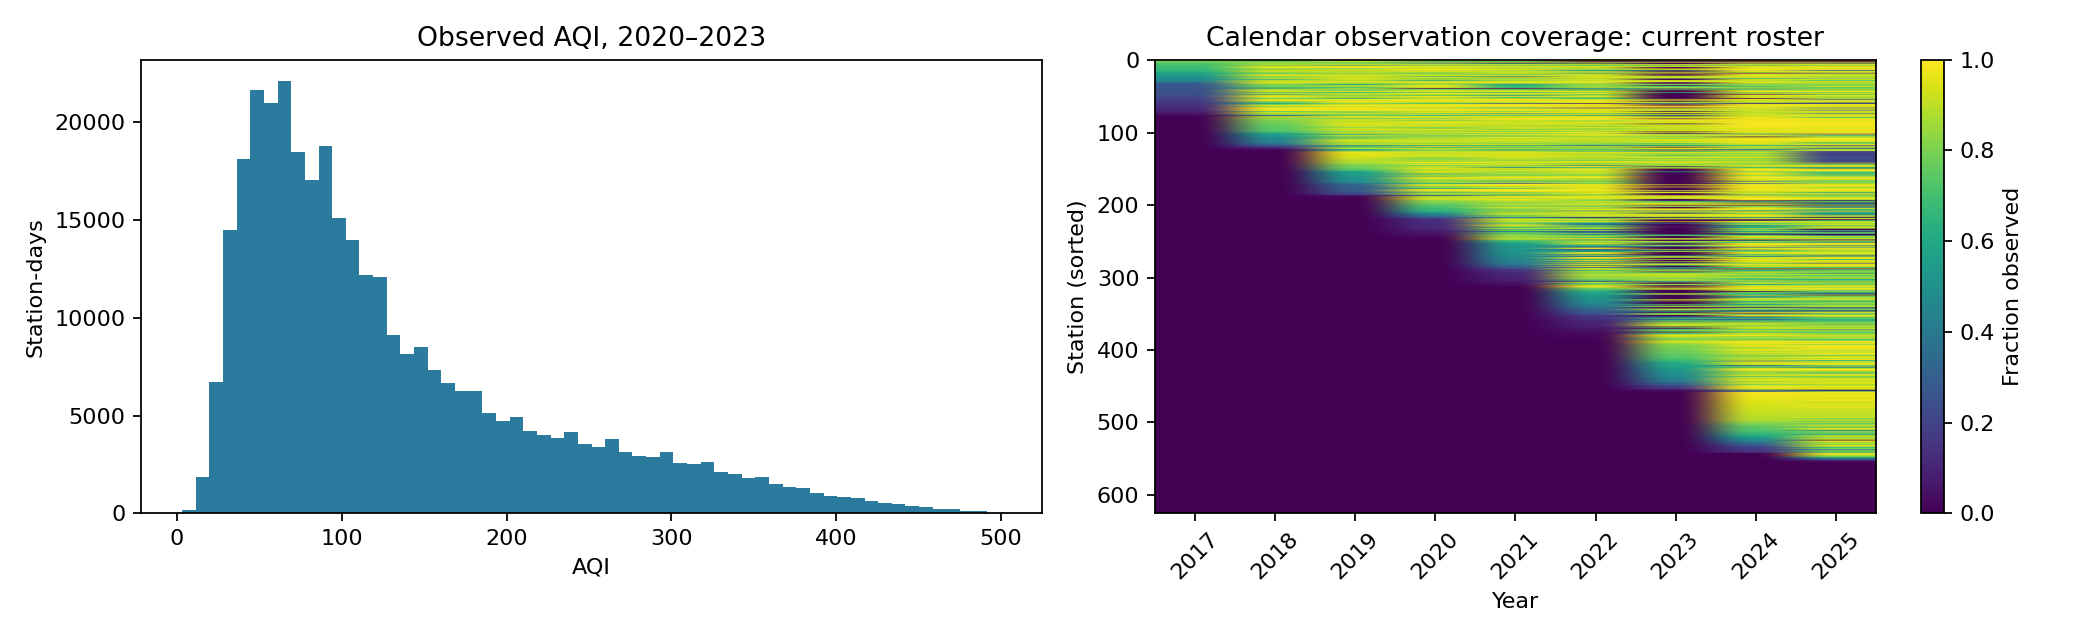

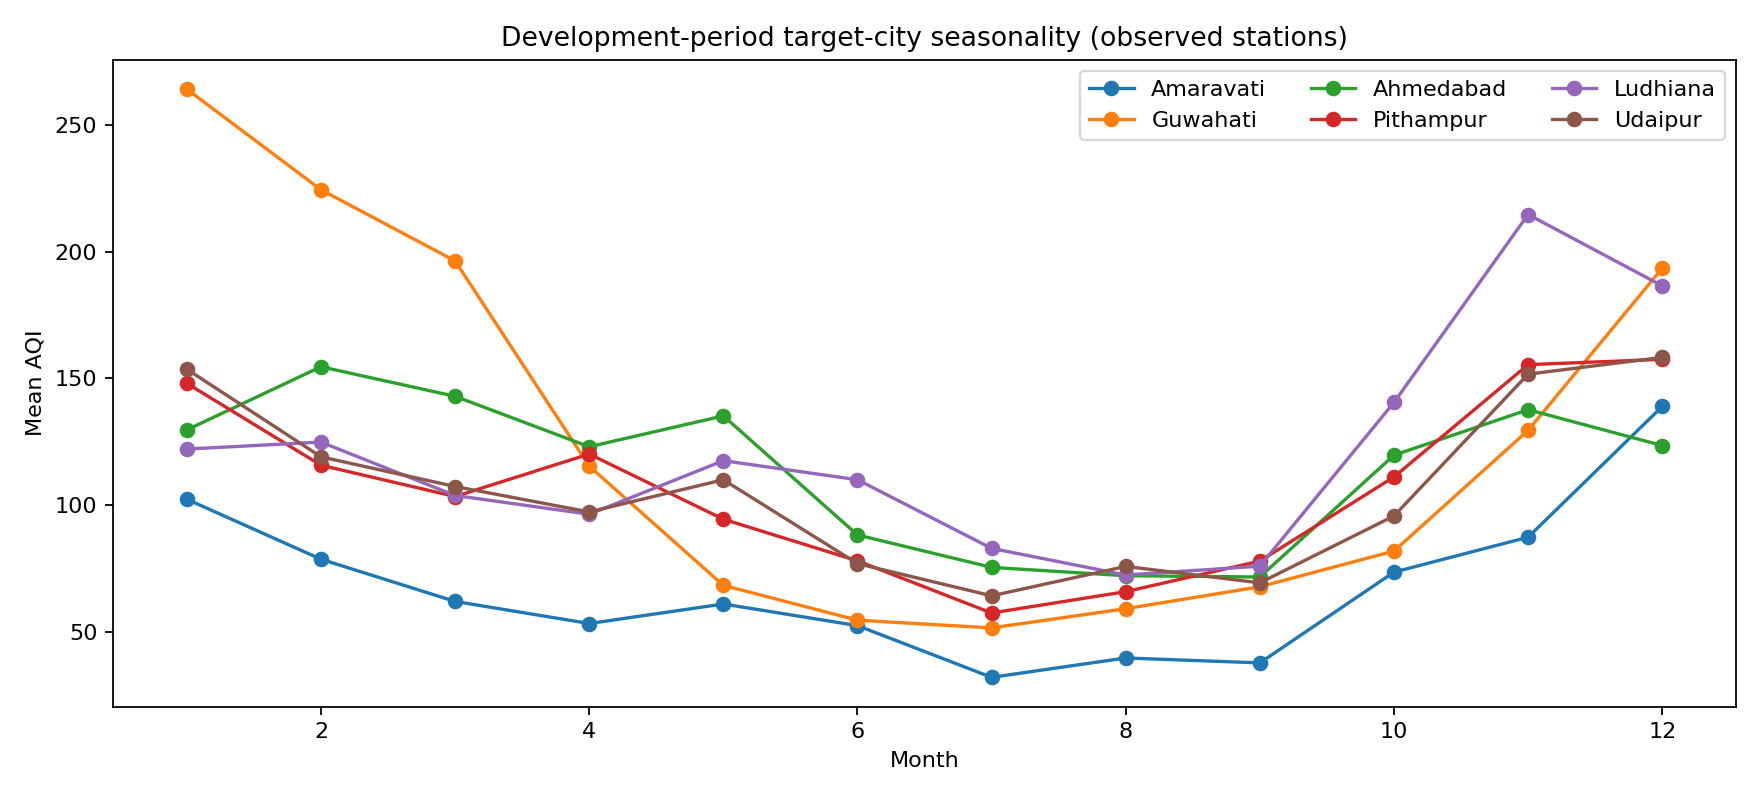

,station_id,city,lag_1,lag_2,lag_3,lag_7,lag_14
0,113,Delhi,0.879596,0.791900,0.741788,0.690028,0.655536
1,1390,Alwar,0.732846,0.594565,0.546022,0.445086,0.320990
2,1392,Ajmer,0.637487,0.527885,0.442853,0.299640,0.231739
3,1395,Pali,0.711131,0.580142,0.506950,0.466284,0.376228
4,1397,Udaipur,0.813690,0.697694,0.650248,0.551709,0.506475
5,1399,Rajamahendravaram,0.877412,0.761784,0.669826,0.514009,0.442978
6,1401,Singrauli,0.885769,0.817931,0.779127,0.733000,0.669783
7,1402,Pithampur,0.818030,0.715736,0.648040,0.539768,0.466469
8,1403,Mandideep,0.833341,0.738944,0.679585,0.609499,0.503113
9,1404,Dewas,0.813709,0.701773,0.635559,0.532352,0.407287


In [3]:
bundle, protocol, source_summary = prepare(SOURCE, OUT/'data')
display(pd.Series(source_summary))
display(pd.read_csv(OUT/'data/cohort.csv'))
display(pd.read_csv(OUT/'data/eligibility.csv'))
display(Image(filename=str(OUT/'data/eda_source.png')))
display(Image(filename=str(OUT/'data/eda_seasonality.png')))
display(pd.read_csv(OUT/'data/development_autocorrelation.csv'))


## What the EDA establishes
Coverage determines whether daily sequences can be formed; a high raw observation count does not guarantee consecutive windows. Development-only distributions and lag correlations characterize scale, persistence and seasonal differences. They do not demonstrate a transfer-learning benefit. The candidate thresholds select an availability cohort and do not prove natural data scarcity. All model conclusions follow in notebooks 02 and 03.


In [4]:
display(Markdown('```json\n'+json.dumps(protocol,indent=2)+'\n```'))

```json
{
  "title": "Cross-City Transfer Learning for AQI Forecasting in Data-Scarce Indian Regions",
  "design": "retrospective, frozen before this run; old pilot results and broad coverage already inspected",
  "source_release_sha256": "014fa6ab88854a9649e4d903483d516be5b4b5ecf482ecd497e291cdf1a89811",
  "source_period": "2017\u20132025; modeling 2020\u20132025",
  "targets": [
    "Amaravati",
    "Guwahati",
    "Ahmedabad",
    "Pithampur",
    "Ludhiana",
    "Udaipur"
  ],
  "dev_cities": [
    "Chandigarh",
    "Dewas",
    "Jalandhar",
    "Ajmer"
  ],
  "station_selection": "at least 80% observed each2020\u20132025; one per city_code ranked by2020\u20132023 observed days, numeric ID tie-break",
  "target_selection": "six untested pilot cities in different states, chosen before forecast inspection; convenience availability cohort",
  "source_geography_guard": "exclude any non-target representative station within25km of ANY known station in a target city, including Vatva beside Ahmedabad; current coordinates, not a historic boundary proof",
  "budgets": [
    30,
    90,
    180
  ],
  "budget_definition": "B unique most-recent eligible target label dates <=2023-12-31, shared across3horizons (3B training pairs); preceding input context additionally available",
  "input": "7 consecutive observed daily AQI values, issue-calendar features, horizon; no weather/peers/future inputs",
  "forecast": "direct horizon-conditioned residual output + last AQI; continuous uncapped",
  "horizons": [
    1,
    2,
    3
  ],
  "donor_train": "2020\u20132022",
  "donor_tune": "2023, development cities excluded preliminary fitting",
  "donor_refit": "2020\u20132023 after donor-only setting selection",
  "target_fitting_cutoff": "2023-12-31",
  "secondary_evaluation": "2024Jan4\u2013Dec31, origins>=2024Jan1; never used for tuning",
  "main_evaluation": "2025 all common eligible label dates; frozen2023weights with rolling observed inputs",
  "exclusions": "unmatched identities and insufficient coverage; gaps yield ineligible windows; no imputation of inputs or truth",
  "seeds": [
    17,
    43,
    71
  ],
  "metrics": [
    "MAE",
    "RMSE",
    "bias",
    "persistence-relative skill"
  ],
  "uncertainty": "seed-average paired losses; within-city14calendar-day block bootstrap, macro6city mean; conditional on these6cities",
  "limitations": [
    "station not city average",
    "simulated fitting-label scarcity not naturally sparse monitoring",
    "last-B selection confounds recency and season",
    "test availability used for eligibility, not performance",
    "target cities convenience sample",
    "frozen2023model ages through2025",
    "daily nominal1\u20133days approximate24\u201372hours; publication latency not verified",
    "CPCB current roster not historic census"
  ]
}
```

## Research sources
The design follows published distinctions between global/local models and gradient-based meta-learning. Citations justify methods, not a claim that these methods must improve AQI.
- [MAML, Finn et al. (2017)](https://proceedings.mlr.press/v70/finn17a.html): task support adaptation and held-out query loss.
- [First-Order Meta-Learning Algorithms, Nichol et al. (2018)](https://arxiv.org/abs/1803.02999): Reptile and first-order MAML are distinct algorithms.
- [Global and Local Forecasting Models, Montero-Manso & Hyndman](https://arxiv.org/abs/2008.00444).
- [Forecasting: Principles and Practice — benchmark methods](https://otexts.com/fpp3/toolbox.html).
- [GRU encoder-decoder, Cho et al.](https://arxiv.org/abs/1406.1078).
- [scikit-learn Ridge documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html).
- [Official CPCB archive](https://airquality.cpcb.gov.in/ccr/#/repository/aqi).
